# Business Insights
Definition: Business insights are meaningful conclusions derived from data analysis that help businesses understand what is happening, why it may be happening, and what action they could take.
In EDA, creating graphs is only one step. The important part is converting what we observe in the data into useful business information.

### Example
Suppose an online store sells three product categories.
- Visualization: A bar chart shows sales by category.
- Observation: Category A has the highest sales, while Category C has the lowest.
- Business insight: Category C may be underperforming compared with Category A.
- Recommended action: Investigate Category C's pricing, product availability, marketing, and customer demand before deciding how to improve sales.
### Real-world examples:
- A hospital finds that patient waiting times are longer in the evening than in the morning.
- An online shopping platform finds that customers abandon their carts more frequently when delivery charges are high.
### Business examples:
- A sales manager discovers that a few products generate most of the company's revenue.
- A customer-support manager discovers that complaints increase after a new product release.
### AI/ML use case: 
Data scientists use EDA findings to identify useful features, understand customer behavior, detect anomalies, and develop hypotheses for predictive models.

### Create a business dataset
We will use an online retail dataset for this notebook. It includes product categories, transactions, revenue, customers, discounts, and customer ratings.

The same dataset will be used to identify patterns, trends, relationships, anomalies, business problems, interesting segments, and opportunities

In [1]:
%mamba install pandas

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 4.884 seconds
  Name    Version  Build                Channel
-------------------------------------------------------------
+ pandas  3.1.0    np23py313h124dbc7_0  emscripten-forge-4x
- pip     26.2.2   pyh145f28c_0         conda-forge


In [2]:
%mamba install seaborn

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas, seaborn
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 3.480 seconds
  Name          Version  Build                Channel
-------------------------------------------------------------------
+ patsy         1.0.3    py313h1804a44_0      emscripten-forge-4x
+ seaborn       0.13.2   hd8ed1ab_3           conda-forge
+ seaborn-base  0.13.2   pyhd8ed1ab_3         conda-forge
+ statsmodels   0.15.0   np23py313h07ed413_0  emscripten-forge-4x


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.DataFrame({
    "Order_ID": range(101, 113),
    "Category": [
        "A", "A", "A", "A",
        "B", "B", "B", "B",
        "C", "C", "C", "C"
    ],
    "Transactions": [
        100, 120, 110, 130,
        90, 95, 100, 105,
        95, 100, 105, 100
    ],
    "Revenue": [
        10000, 12000, 11000, 13000,
        7200, 7600, 8000, 8400,
        4750, 5000, 5250, 5000
    ],
    "Discount_Percent": [
        5, 5, 10, 5,
        10, 10, 15, 10,
        5, 5, 5, 20
    ],
    "Customer_Rating": [
        4.5, 4.6, 4.4, 4.7,
        4.0, 4.1, 3.9, 4.0,
        3.2, 3.4, 3.1, 2.5
    ]
})

df

,Order_ID,Category,Transactions,Revenue,Discount_Percent,Customer_Rating
0,101,A,100,10000,5,4.5
1,102,A,120,12000,5,4.6
2,103,A,110,11000,10,4.4
3,104,A,130,13000,5,4.7
4,105,B,90,7200,10,4.0
5,106,B,95,7600,10,4.1
6,107,B,100,8000,15,3.9
7,108,B,105,8400,10,4.0
8,109,C,95,4750,5,3.2
9,110,C,100,5000,5,3.4


In [4]:
print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

print("\nCategory summary:")
print(
    df.groupby("Category")
      .agg(
          Total_Transactions=("Transactions", "sum"),
          Total_Revenue=("Revenue", "sum"),
          Average_Rating=("Customer_Rating", "mean")
      )
      .round(2)
)

Dataset shape: (12, 6)

Missing values:
Order_ID            0
Category            0
Transactions        0
Revenue             0
Discount_Percent    0
Customer_Rating     0
dtype: int64

Category summary:
          Total_Transactions  Total_Revenue  Average_Rating
Category                                                   
A                        460          46000            4.55
B                        390          31200            4.00
C                        400          20000            3.05


## Identify important patterns
Definition: A pattern is a repeated or consistent behavior in the data that helps us understand how a business operates.
### Why is it important?
Patterns can reveal which products perform well, which customers spend more, or which areas consistently generate lower results.
### Business question: 
Which product category contributes the most revenue?

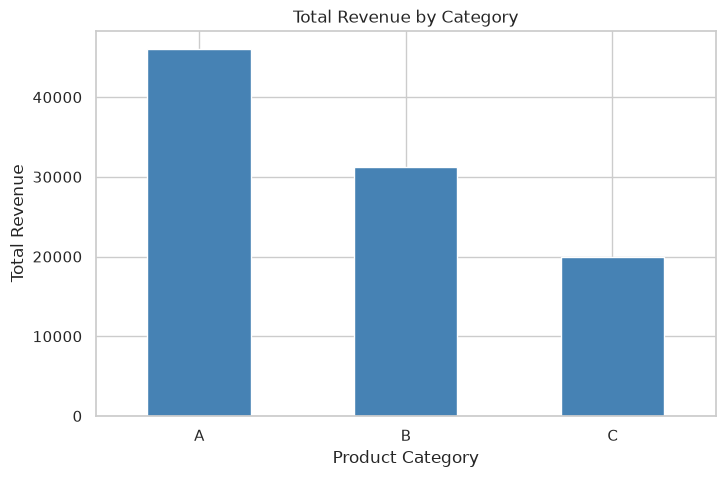

Category
A    46000
B    31200
C    20000
Name: Revenue, dtype: int64


In [5]:
category_revenue = (
    df.groupby("Category")["Revenue"]
      .sum()
      .sort_values(ascending=False)
)

category_revenue.plot(
    kind="bar",
    figsize=(8, 5),
    color="steelblue"
)

plt.title("Total Revenue by Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=0)
plt.show()

print(category_revenue)

### Interpretation
- Category A generates the highest revenue.
- Category B generates less revenue than Category A.
- Category C generates the lowest revenue.
### Business insight
Category A contributes ₹49,000 in revenue, compared with ₹20,000 from Category C. Category C generates less than half the revenue of Category A, despite having a similar total number of transactions.
This difference suggests that the business should investigate the revenue generated per transaction in Category C.

### AI/ML use case: 
Patterns help identify potentially important features for predicting sales or classifying high-performing and low-performing products.

## Identify trends
Definition: A trend is a general upward, downward, or stable movement in a metric over time.
### Why is it important?
Trends help businesses understand how performance changes over time and whether an improvement or decline is continuing.
Our original dataset does not contain dates, so we will create a separate monthly sales dataset for this example.

### Business question: 
Are monthly sales increasing or decreasing?

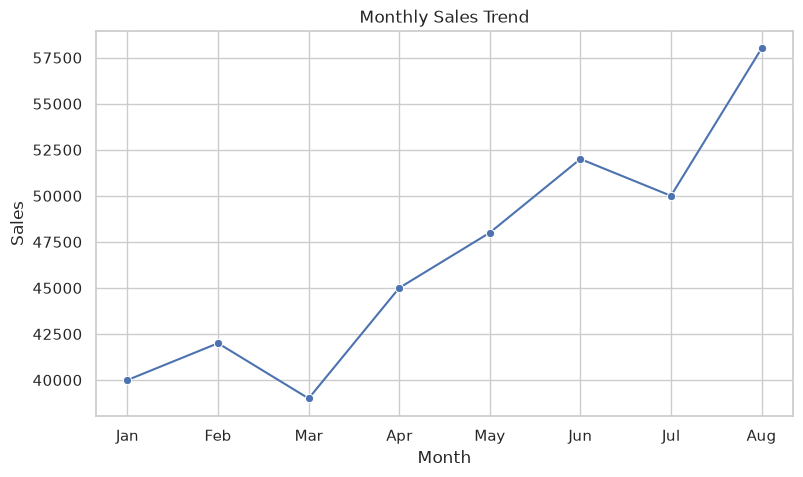

January sales: 40000
August sales: 58000
January to August growth: 45.00%


In [6]:
monthly_sales = pd.DataFrame({
    "Month": [
        "Jan", "Feb", "Mar", "Apr",
        "May", "Jun", "Jul", "Aug"
    ],
    "Sales": [
        40000, 42000, 39000, 45000,
        48000, 52000, 50000, 58000
    ]
})

plt.figure(figsize=(9, 5))

sns.lineplot(
    data=monthly_sales,
    x="Month",
    y="Sales",
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.show()

print("January sales:", monthly_sales["Sales"].iloc[0])
print("August sales:", monthly_sales["Sales"].iloc[-1])

growth = (
    (monthly_sales["Sales"].iloc[-1]
     - monthly_sales["Sales"].iloc[0])
    / monthly_sales["Sales"].iloc[0]
) * 100

print(f"January to August growth: {growth:.2f}%")

### Interpretation
- Sales increase from ₹40,000 in January to ₹58,000 in August.
- Sales decline temporarily in March and July.
- The overall movement is upward.
### Business insight
Sales increased by 45% between January and August in this example. The business should investigate which products, campaigns, or seasonal factors contributed to the increase and whether the growth can be sustained.

### AI/ML use case: 
Trend analysis is useful for forecasting sales, predicting demand, and identifying seasonal patterns. Eight months of data alone would not be enough to establish a reliable long-term seasonal pattern.

## Identify relationships
Definition: A relationship describes how two or more variables change in relation to each other.
### Why is it important?
Understanding relationships helps businesses discover factors associated with sales, revenue, customer satisfaction, or other outcomes.

### Business question: 
Is a higher customer rating associated with higher revenue?

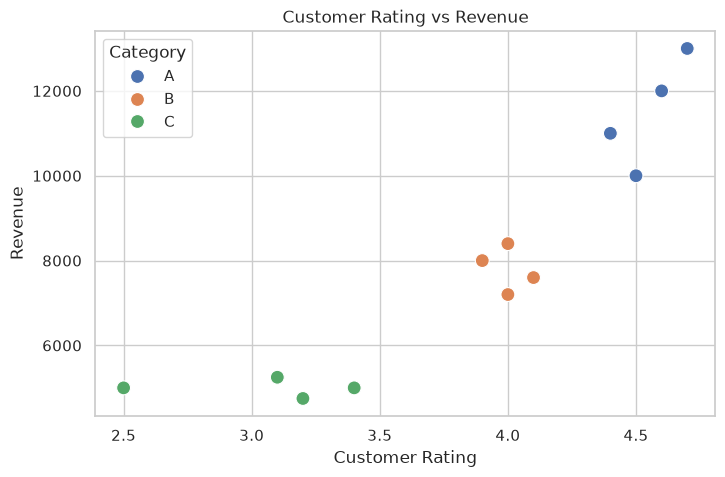

Correlation: 0.91


In [7]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Customer_Rating",
    y="Revenue",
    hue="Category",
    s=100
)

plt.title("Customer Rating vs Revenue")
plt.xlabel("Customer Rating")
plt.ylabel("Revenue")
plt.show()

correlation = df["Customer_Rating"].corr(df["Revenue"])

print(f"Correlation: {correlation:.2f}")

### Interpretation
- Each point represents one record.
- The X-axis represents customer ratings.
- The Y-axis represents revenue.
- The colors identify the product categories.
- The correlation value summarizes the direction and strength of the linear relationship.
### Business insight
The categories with higher average customer ratings also have higher revenue per record in this sample. However, the categories may differ in pricing or other characteristics, so we cannot conclude that higher ratings directly cause higher revenue.

A useful next step is to investigate product pricing, category differences, customer feedback, and repeat purchases.

### AI/ML use case: 
Relationships help identify potentially useful features and guide feature selection. A correlation should be treated as evidence of association, not proof of causation.

## Identify anomalies
Definition: An anomaly is an observation that differs noticeably from the expected behavior or the rest of the data.
### Why is it important?
Anomalies may indicate data-entry errors, unusual customer behavior, fraud, operational problems, or genuine exceptional events.
### Business question: 
Are there orders with unusually high discounts or low customer ratings?

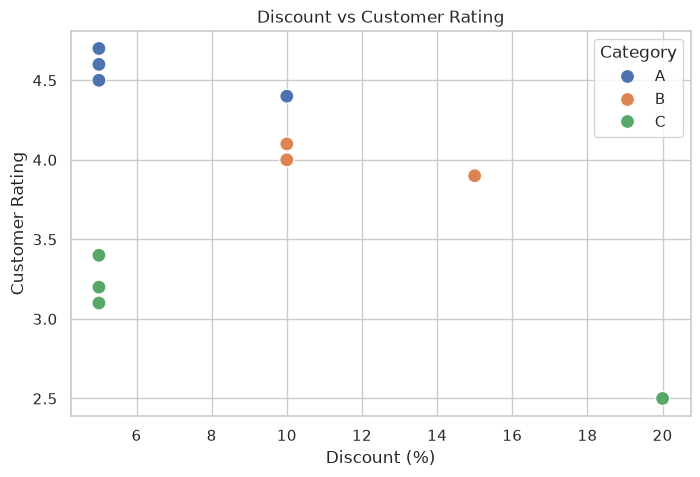

    Order_ID Category  Transactions  Revenue  Discount_Percent  \
11       112        C           100     5000                20   

    Customer_Rating  
11              2.5  


In [8]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Discount_Percent",
    y="Customer_Rating",
    hue="Category",
    s=100
)

plt.title("Discount vs Customer Rating")
plt.xlabel("Discount (%)")
plt.ylabel("Customer Rating")
plt.show()

unusual_records = df[
    (df["Discount_Percent"] >= 20)
    | (df["Customer_Rating"] < 3)
]

print(unusual_records)

### Expected finding: 
The record with Order_ID = 112 has a 20% discount and a customer rating of 2.5. The record with Order_ID = 107 also has a rating below 3? No—its rating is 3.9, so it is not selected by the rating condition. In this dataset, the only selected record is Order 112.
### Interpretation
- Order 112 has a discount that is higher than those on the other records.
- Its customer rating is also the lowest in the dataset.
- The combination is worth investigating, but it does not establish why the customer gave a low rating.
### Business insight
The business should review Order 112's customer feedback, product quality, delivery experience, and discount policy to determine whether a genuine problem occurred.

### AI/ML use case: 
Anomaly detection can help flag unusual transactions, suspicious activity, unexpected sensor readings, and data quality issues.

## Identify potential business problems
Definition: A business problem is an issue in performance, operations, customer experience, or profitability that may require investigation or corrective action.

### Why is it important?
EDA can reveal warning signs early, helping businesses prioritize problems rather than making decisions based on assumptions.
### Business question: 
Is any product category underperforming in both revenue and customer satisfaction?

In [9]:
category_summary = (
    df.groupby("Category")
      .agg(
          Total_Transactions=("Transactions", "sum"),
          Total_Revenue=("Revenue", "sum"),
          Average_Rating=("Customer_Rating", "mean")
      )
)

category_summary["Revenue_Per_Transaction"] = (
    category_summary["Total_Revenue"]
    / category_summary["Total_Transactions"]
)

print(category_summary.round(2))

          Total_Transactions  Total_Revenue  Average_Rating  \
Category                                                      
A                        460          46000            4.55   
B                        390          31200            4.00   
C                        400          20000            3.05   

          Revenue_Per_Transaction  
Category                           
A                           100.0  
B                            80.0  
C                            50.0  


### Interpretation
- Category C has 400 transactions, close to Category A's 460.
- Category C generates much less revenue.
- Category C also has the lowest average customer rating.
### Business insight
Category C may have a combination of low revenue per transaction and poor customer satisfaction. The business should investigate product pricing, quality, returns, and customer feedback before choosing a solution.

### AI/ML use case: 
Combining multiple indicators helps identify products or customer segments that may be at risk of poor performance.

## Identify interesting segments
Definition: Segmentation means dividing data into meaningful groups based on shared characteristics, such as customer type, location, product category, or purchase behavior.

### Why is it important?
Different groups can behave differently. A strategy that works for one segment may not work for another.

### Business question: 
Which product category has the strongest combination of sales and customer satisfaction?

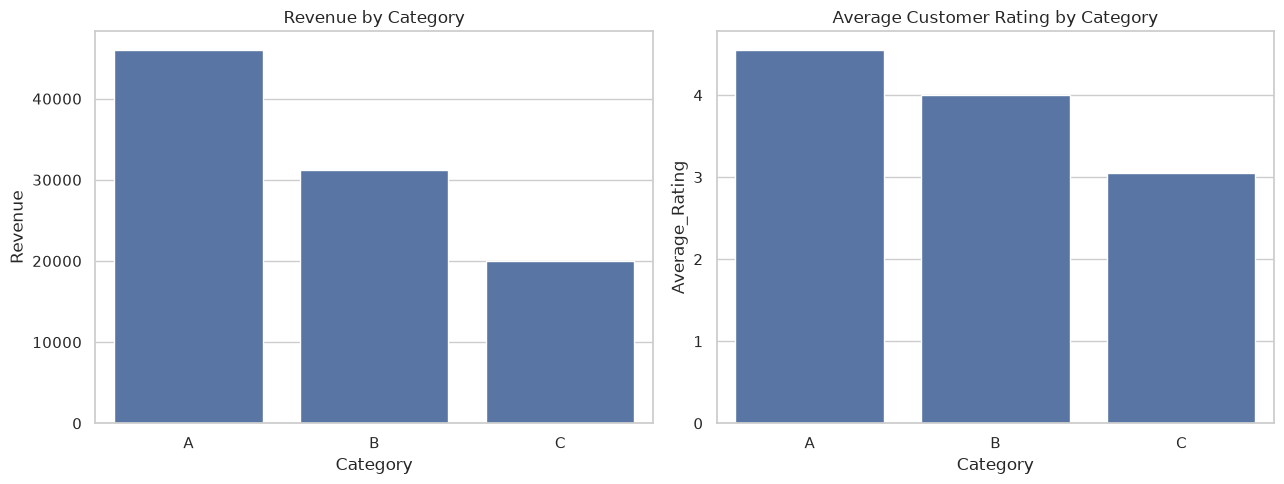

  Category  Revenue  Average_Rating  Transactions
0        A    46000            4.55           460
1        B    31200            4.00           390
2        C    20000            3.05           400


In [10]:
segment_summary = (
    df.groupby("Category")
      .agg(
          Revenue=("Revenue", "sum"),
          Average_Rating=("Customer_Rating", "mean"),
          Transactions=("Transactions", "sum")
      )
      .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(
    data=segment_summary,
    x="Category",
    y="Revenue",
    ax=axes[0]
)
axes[0].set_title("Revenue by Category")

sns.barplot(
    data=segment_summary,
    x="Category",
    y="Average_Rating",
    ax=axes[1]
)
axes[1].set_title("Average Customer Rating by Category")

plt.tight_layout()
plt.show()

print(segment_summary.round(2))

### Interpretation
- Category A leads in both revenue and average customer rating.
- Category B performs between A and C on both measures.
- Category C has the lowest revenue and rating.
### Business insight
Category A is a potential segment to study for practices that could be applied elsewhere, while Category C is a priority for further investigation. The business should compare product types, prices, marketing, and customer feedback before assuming that Category A's approach will work for Category C.

### AI/ML use case: 
Customer and product segmentation can support targeted marketing, personalized recommendations, and differentiated customer-retention strategies.

## Identify potential opportunities
Definition: A business opportunity is a possible way to improve revenue, profitability, customer satisfaction, or operational efficiency based on evidence from the data.

### Why is it important?
EDA should not only identify problems. It should also help businesses discover where improvements or growth may be possible.
### Business question: 
Which category might benefit most from a targeted improvement strategy?

In [11]:
opportunity = (
    df.groupby("Category")
      .agg(
          Revenue=("Revenue", "sum"),
          Transactions=("Transactions", "sum"),
          Average_Rating=("Customer_Rating", "mean")
      )
)

opportunity["Revenue_Per_Transaction"] = (
    opportunity["Revenue"] / opportunity["Transactions"]
)

opportunity = opportunity.sort_values(
    "Revenue_Per_Transaction",
    ascending=True
)

print(opportunity.round(2))

          Revenue  Transactions  Average_Rating  Revenue_Per_Transaction
Category                                                                
C           20000           400            3.05                     50.0
B           31200           390            4.00                     80.0
A           46000           460            4.55                    100.0


### Interpretation
Category C has the lowest revenue per transaction and lowest average customer rating. This makes it a reasonable candidate for a focused improvement investigation.
### Potential opportunities
- Improve customer experience: Review low ratings and identify recurring complaints.
- Review product pricing: Compare prices and customer value across categories.
- Improve product quality: Investigate returns, defects, and negative feedback.
- Test targeted promotions: Run a controlled experiment to see whether a promotion improves sales without hurting profitability.
- Study successful products: Examine what differentiates high-performing Category A products.
### Business insight
Category C offers a potential improvement opportunity because its revenue per transaction and customer ratings are relatively low. Any proposed change should be tested and measured rather than assumed to work.

### AI/ML use case: 
Predictive models can help identify which products or customers may benefit from targeted interventions. A controlled experiment can then help measure whether the intervention actually improves outcomes.